# NumCompute streaming classification demo

This notebook loads a CSV using the package I/O module, divides observations into sequential chunks, performs prequential evaluation, incrementally updates preprocessing and buffered decision trees, and visualises the resulting metrics.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'numcompute_stream').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from numcompute_stream import DecisionTreeClassifier, Imputer, Pipeline, StreamTrainer
from numcompute_stream.io import read_numeric_csv
from numcompute_stream.visualise import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth

## 1. Load the CSV using the custom NumPy I/O module

In [2]:
data_path = ROOT / 'demo' / 'data' / 'stream_classification.csv'
data = read_numeric_csv(data_path)
X, y = data[:, :-1], data[:, -1].astype(int)
print('Loaded shape:', data.shape, '| features:', X.shape, '| labels:', np.unique(y, return_counts=True))

Loaded shape: (720, 5) | features: (720, 4) | labels: (array([0, 1]), array([371, 349]))


## 2. Reserve a final holdout and split the training stream into chunks

In [3]:
X_stream, y_stream = X[:600], y[:600]
X_test, y_test = X[600:], y[600:]
chunk_size = 60
chunks = [(X_stream[i:i+chunk_size], y_stream[i:i+chunk_size]) for i in range(0, len(y_stream), chunk_size)]
print('Number of chunks:', len(chunks), '| chunk size:', chunk_size, '| holdout:', len(y_test))

Number of chunks: 10 | chunk size: 60 | holdout: 120


## 3. Incremental pipeline and buffered decision tree

The imputer updates its feature statistics for each chunk. The tree retrains whenever its internal buffer reaches 80 samples. Each chunk is scored before it is used for training (prequential evaluation).

In [4]:
tree = DecisionTreeClassifier(max_depth=5, criterion='gini', min_samples_split=2, buffer_size=80, random_state=7)
pipeline = Pipeline([('imputer', Imputer(strategy='mean')), ('tree', tree)])
trainer = StreamTrainer(tree, pipeline=pipeline, rolling_window=3)
logs = []
for chunk_X, chunk_y in chunks:
    logs.append(trainer.fit_chunk(chunk_X, chunk_y))
print('Retrains:', tree.retrain_count_, '| buffered samples:', tree.buffered_samples_)
print('Last log:', logs[-1])

Retrains: 5 | buffered samples: 0
Last log: {'chunk': 10, 'n_samples': 60, 'prequential_accuracy': 0.8333333333333334, 'post_update_accuracy': 1.0, 'cumulative_accuracy': 0.80625, 'precision': 0.808181484652073, 'recall': 0.80625, 'f1': 0.8059459482957239, 'retrain_count': 5, 'buffered_samples': 0, 'memory_bytes': 0}


## 4. Visualise accuracy, update time and latest predictions

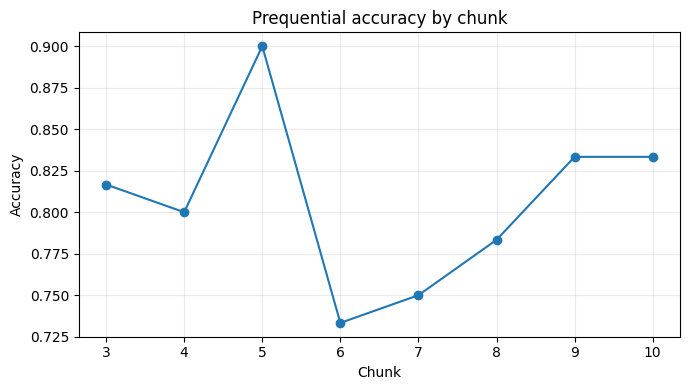

Holdout accuracy: 0.8666666666666667


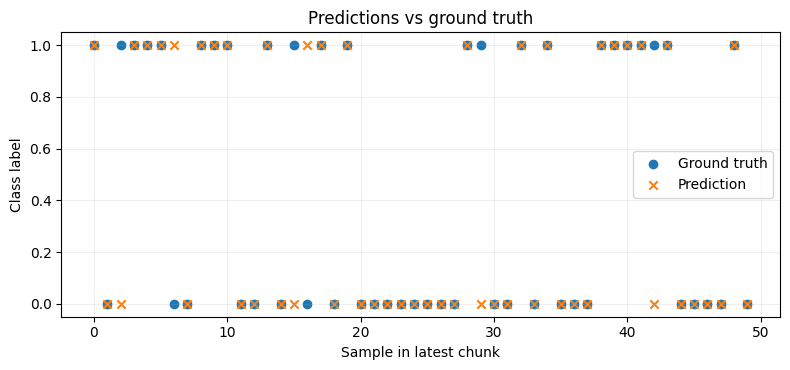

In [5]:
prequential = [np.nan if r['prequential_accuracy'] is None else r['prequential_accuracy'] for r in logs]
fig = plot_metric_over_time(prequential, title='Prequential accuracy by chunk', ylabel='Accuracy', show=False)
plt.show()
print('Holdout accuracy:', trainer.score(X_test, y_test))
pred = pipeline.predict(X_test)
fig = plot_predictions_vs_ground_truth(y_test[:50], pred[:50], show=False)
plt.show()

## 5. Compare two buffer sizes

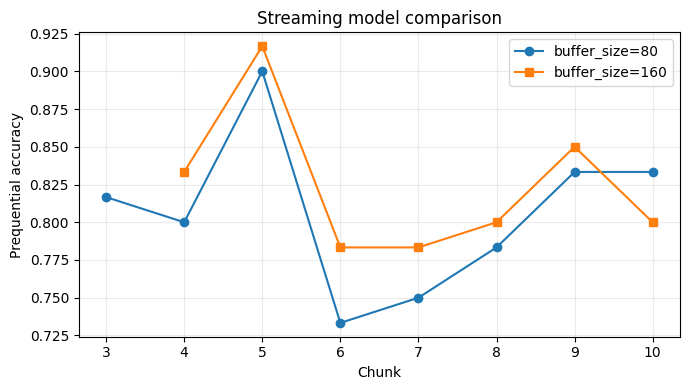

Holdout scores: 0.8666666666666667 0.8


In [6]:
def run_buffer(buffer_size):
    m = DecisionTreeClassifier(max_depth=5, buffer_size=buffer_size, random_state=7)
    t = StreamTrainer(m)
    values = []
    for cx, cy in chunks:
        entry = t.fit_chunk(cx, cy)
        values.append(np.nan if entry['prequential_accuracy'] is None else entry['prequential_accuracy'])
    return values, m
acc_80, model_80 = run_buffer(80)
acc_160, model_160 = run_buffer(160)
compare_models(acc_80, acc_160, labels=('buffer_size=80','buffer_size=160'), ylabel='Prequential accuracy', show=True)
print('Holdout scores:', model_80.score(X_test, y_test), model_160.score(X_test, y_test))

## Interpretation

Smaller buffers trigger more frequent retraining and can adapt sooner, but incur more model-building work. Larger buffers reduce retraining frequency and increase the number of samples available to each fit, but may react more slowly to distribution changes. The measured results depend on the dataset, chunk order, tree depth and machine.